In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

In [3]:
import seaborn as sns

In [4]:
from sklearn.preprocessing import StandardScaler

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
from sklearn.linear_model import LinearRegression

In [7]:
from sklearn.metrics import mean_absolute_error

In [8]:
from sklearn.metrics import mean_squared_error

In [63]:
from sklearn.metrics import r2_score

In [9]:
car_info=pd.read_csv("C:\\Users\\acer\\Downloads\\car_csv\\car data.csv")
car_info

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.90,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.00,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.50,9000,Diesel,Dealer,Manual,0


In [10]:
car_info.head(10)

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
5,vitara brezza,2018,9.25,9.83,2071,Diesel,Dealer,Manual,0
6,ciaz,2015,6.75,8.12,18796,Petrol,Dealer,Manual,0
7,s cross,2015,6.50,8.61,33429,Diesel,Dealer,Manual,0
8,ciaz,2016,8.75,8.89,20273,Diesel,Dealer,Manual,0
9,ciaz,2015,7.45,8.92,42367,Diesel,Dealer,Manual,0


In [11]:
car_info.shape

(301, 9)

In [12]:
car_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


In [13]:
car_info.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [14]:
car_info.isnull().sum()

Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

In [15]:
car_info.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [16]:
car_info["Fuel_Type"].value_counts()

Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64

In [17]:
car_info["Transmission"].value_counts()

Transmission
Manual       261
Automatic     40
Name: count, dtype: int64

In [18]:
car_info["Seller_Type"].value_counts()

Seller_Type
Dealer        195
Individual    106
Name: count, dtype: int64

In [19]:
plt.style.available

['Solarize_Light2',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'petroff6',
 'petroff8',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

In [20]:
plt.style.use("ggplot")

In [21]:
fuel_info=car_info["Fuel_Type"]
seller_info=car_info["Seller_Type"]

In [22]:
transmission_info=car_info["Transmission"]

In [23]:
selling_price=car_info["Selling_Price"]

In [24]:
fuel_info

0      Petrol
1      Diesel
2      Petrol
3      Petrol
4      Diesel
        ...  
296    Diesel
297    Petrol
298    Petrol
299    Diesel
300    Petrol
Name: Fuel_Type, Length: 301, dtype: str

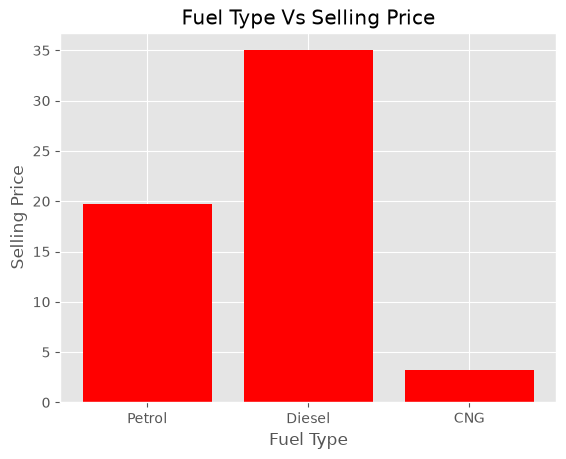

In [25]:
plt.bar(fuel_info,selling_price,color="red")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.title("Fuel Type Vs Selling Price")
plt.show()

In [26]:
car_info.groupby("Fuel_Type")["Selling_Price"].mean()

Fuel_Type
CNG        3.100000
Diesel    10.278500
Petrol     3.264184
Name: Selling_Price, dtype: float64

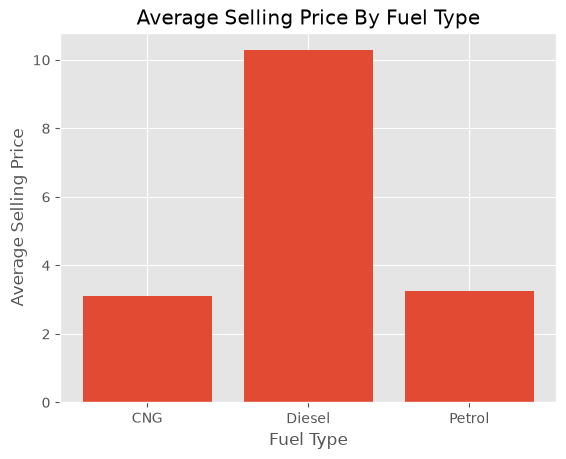

In [27]:
average_price=car_info.groupby("Fuel_Type")["Selling_Price"].mean()
plt.bar(average_price.index,average_price.values)
plt.xlabel("Fuel Type")
plt.ylabel("Average Selling Price")
plt.title("Average Selling Price By Fuel Type")
plt.show();

In [28]:
seller_average=car_info.groupby("Seller_Type")["Selling_Price"].mean()
seller_average

Seller_Type
Dealer        6.721692
Individual    0.870943
Name: Selling_Price, dtype: float64

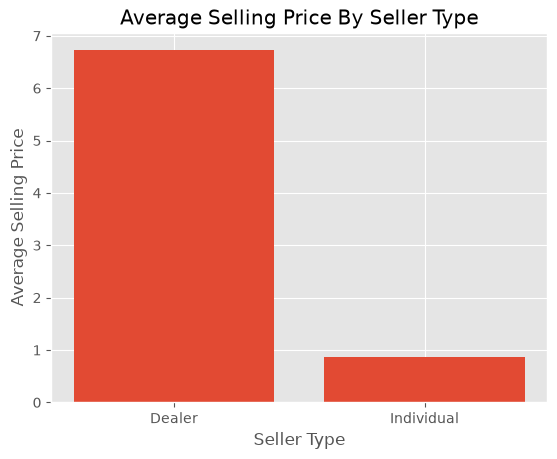

In [29]:
plt.bar(seller_average.index,seller_average.values)
plt.xlabel("Seller Type")
plt.ylabel("Average Selling Price")
plt.title("Average Selling Price By Seller Type")
plt.show();

In [30]:
transmission_average=car_info.groupby("Transmission")["Selling_Price"].mean()
transmission_average

Transmission
Automatic    9.420000
Manual       3.931992
Name: Selling_Price, dtype: float64

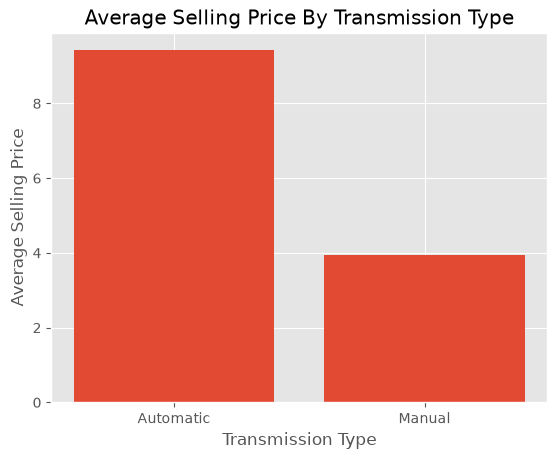

In [31]:
plt.bar(transmission_average.index,transmission_average.values)
plt.xlabel("Transmission Type")
plt.ylabel("Average Selling Price")
plt.title("Average Selling Price By Transmission Type")
plt.show();

In [32]:
cng_data=car_info.groupby("Fuel_Type").get_group("CNG")
cng_data

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
18,wagon r,2015,3.25,5.09,35500,CNG,Dealer,Manual,0
35,sx4,2011,2.95,7.74,49998,CNG,Dealer,Manual,0


In [33]:
cng_data.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,2.000000,2.000000,2.000000,2.000000,2.0
mean,2013.000000,3.100000,6.415000,42749.000000,0.0
std,2.828427,0.212132,1.873833,10251.634114,0.0
min,2011.000000,2.950000,5.090000,35500.000000,0.0
25%,2012.000000,3.025000,5.752500,39124.500000,0.0
50%,2013.000000,3.100000,6.415000,42749.000000,0.0
75%,2014.000000,3.175000,7.077500,46373.500000,0.0
max,2015.000000,3.250000,7.740000,49998.000000,0.0


In [34]:
car_info.replace({"Fuel_Type":{"Petrol":0,"Diesel":1,"CNG":2}},inplace=True)
car_info["Fuel_Type"].value_counts()

Fuel_Type
0    239
1     60
2      2
Name: count, dtype: int64

In [35]:
car_info.replace({"Seller_Type":{"Dealer":0,"Individual":1}},inplace=True)
car_info["Seller_Type"].value_counts()

Seller_Type
0    195
1    106
Name: count, dtype: int64

In [36]:
car_info.replace({"Transmission":{"Manual":0,"Automatic":1}},inplace=True)
car_info["Transmission"].value_counts()

Transmission
0    261
1     40
Name: count, dtype: int64

In [37]:
car_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(3), str(1)
memory usage: 21.3+ KB


In [38]:
car_info["Fuel_Type"]=car_info["Fuel_Type"].astype(int)
car_info["Seller_Type"]=car_info["Seller_Type"].astype(int)
car_info["Transmission"]=car_info["Transmission"].astype(int)

In [39]:
car_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    int64  
 6   Seller_Type    301 non-null    int64  
 7   Transmission   301 non-null    int64  
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(6), str(1)
memory usage: 21.3 KB


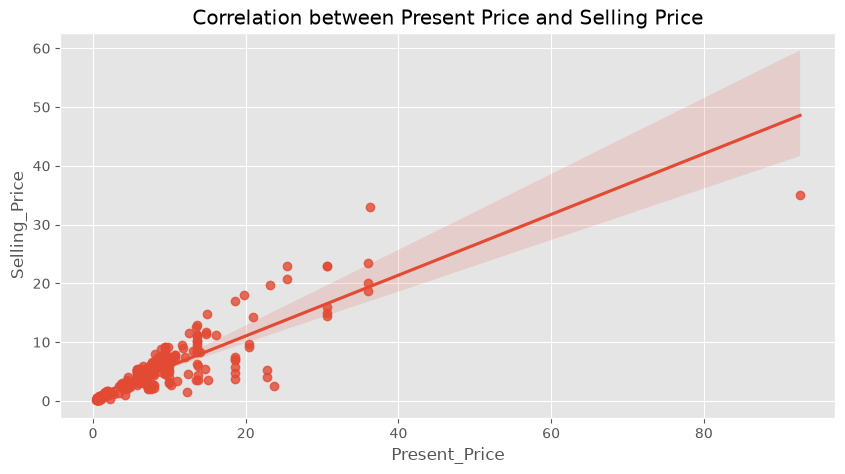

In [40]:
plt.figure(figsize=(10,5))
plt.title("Correlation between Present Price and Selling Price")
sns.regplot(x=car_info["Present_Price"],y=car_info["Selling_Price"])
plt.show();

In [41]:
input_data=car_info.drop(columns=["Car_Name","Selling_Price"])
input_data.head()

,Year,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,2014,5.59,27000,0,0,0,0
1,2013,9.54,43000,1,0,0,0
2,2017,9.85,6900,0,0,0,0
3,2011,4.15,5200,0,0,0,0
4,2014,6.87,42450,1,0,0,0


In [42]:
output_data=car_info["Selling_Price"]
output_data.head()

0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64

In [43]:
print(input_data.shape)
print(output_data.shape)

(301, 7)
(301,)


In [44]:
input_data_encoded=pd.get_dummies(
    input_data,
    columns=["Fuel_Type","Seller_Type","Transmission"],
    dtype=int
)
input_data_encoded.head()

,Year,Present_Price,Kms_Driven,Owner,Fuel_Type_0,Fuel_Type_1,Fuel_Type_2,Seller_Type_0,Seller_Type_1,Transmission_0,Transmission_1
0,2014,5.59,27000,0,1,0,0,1,0,1,0
1,2013,9.54,43000,0,0,1,0,1,0,1,0
2,2017,9.85,6900,0,1,0,0,1,0,1,0
3,2011,4.15,5200,0,1,0,0,1,0,1,0
4,2014,6.87,42450,0,0,1,0,1,0,1,0


In [45]:
print(input_data_encoded.shape)
input_data_encoded.head()

(301, 11)


,Year,Present_Price,Kms_Driven,Owner,Fuel_Type_0,Fuel_Type_1,Fuel_Type_2,Seller_Type_0,Seller_Type_1,Transmission_0,Transmission_1
0,2014,5.59,27000,0,1,0,0,1,0,1,0
1,2013,9.54,43000,0,0,1,0,1,0,1,0
2,2017,9.85,6900,0,1,0,0,1,0,1,0
3,2011,4.15,5200,0,1,0,0,1,0,1,0
4,2014,6.87,42450,0,0,1,0,1,0,1,0


In [46]:
scaler=StandardScaler()

In [47]:
x_train,x_test,y_train,y_test=train_test_split(
    input_data_encoded,
    output_data,
    test_size=0.2,
    random_state=42
)

In [48]:
input_data_train_scaled=scaler.fit_transform(x_train)

In [49]:
input_data_test_scaled=scaler.transform(x_test)

In [50]:
print(f"original x_train {x_train.shape}")
print(f"scaled x_train {input_data_train_scaled.shape}")
print(f"original x_test {x_test.shape}")
print(f"scaled x_test {input_data_test_scaled.shape}")


original x_train (240, 11)
scaled x_train (240, 11)
original x_test (61, 11)
scaled x_test (61, 11)


In [51]:
print(input_data_encoded.columns.tolist())
print(x_train.columns.tolist())

['Year', 'Present_Price', 'Kms_Driven', 'Owner', 'Fuel_Type_0', 'Fuel_Type_1', 'Fuel_Type_2', 'Seller_Type_0', 'Seller_Type_1', 'Transmission_0', 'Transmission_1']
['Year', 'Present_Price', 'Kms_Driven', 'Owner', 'Fuel_Type_0', 'Fuel_Type_1', 'Fuel_Type_2', 'Seller_Type_0', 'Seller_Type_1', 'Transmission_0', 'Transmission_1']


In [52]:
model=LinearRegression()

In [53]:
model.fit(input_data_train_scaled,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ 1.02, 3.85,-0.26,...,-0.29,-0.27, 0.27]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.642
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](11,)","[28.32,22.3 ,19.19,..., 0. , 0. , 0. ]"


In [54]:
predictions=model.predict(input_data_test_scaled)
print(predictions)

[ 2.95534303  8.178939    6.45427257 -1.42417501  9.08889914  7.41825441
  1.33644285  0.84027217  1.36501949  7.49026806  9.11830017  0.58573931
  8.41612774  3.42316502  6.90043281  3.04988309  0.48448171 10.70970753
  1.75207005  2.34571752  0.39746889  8.11925338  6.62469317  2.65939066
  0.78280554  3.69330765  5.24815462  2.82676351  2.13640446  1.75237686
  0.39730155  9.11750503 -0.66188053  2.29098014  8.57067341  4.4910324
  7.20530369  7.53824015  2.89101139  7.93588794  3.93585154  4.27133211
  4.33205704  0.6008847   7.34025071  0.47602539  7.29187681 11.23125597
  3.13805132  5.38262985  6.7988422   2.17888955 20.63303305 17.0015261
  7.50717349  9.69621308  4.47478116  8.97377615  1.82294639  7.60416734
  0.22226536]


In [55]:
comparison=pd.DataFrame({
    "Actual_Price":y_test.values,
    "Predictions":predictions
})

comparison.head()

,Actual_Price,Predictions
0,0.35,2.955343
1,10.11,8.178939
2,4.95,6.454273
3,0.15,-1.424175
4,6.95,9.088899


In [56]:
mae=mean_absolute_error(y_test,predictions)
print(f"Mean Absolute Error {mae}")

Mean Absolute Error 1.2162256821297066


In [57]:
mse=mean_squared_error(y_test,predictions)
print(f"Mean Squared Error {mse}")

Mean Squared Error 3.4788039706379013


In [58]:
print("Minimum predicted price:", predictions.min())
print("Maximum predicted price:", predictions.max())
print("Number of negative predictions:", (predictions < 0).sum())

Minimum predicted price: -1.424175014000567
Maximum predicted price: 20.633033047681224
Number of negative predictions: 2


In [59]:
negative_predictions=comparison[comparison["Predictions"]<0].copy()
negative_predictions

,Actual_Price,Predictions
3,0.15,-1.424175
32,0.45,-0.661881


In [60]:
negative_predictions["Error"]=(
    negative_predictions["Predictions"]-negative_predictions["Actual_Price"]
)
negative_predictions

,Actual_Price,Predictions,Error
3,0.15,-1.424175,-1.574175
32,0.45,-0.661881,-1.111881


In [61]:
coefficient_info = pd.DataFrame({
    "Feature": input_data_encoded.columns,
    "Coefficient": model.coef_
})

coefficient_info

,Feature,Coefficient
0,Year,1.018523
1,Present_Price,3.850784
2,Kms_Driven,-0.257158
3,Owner,-0.243345
4,Fuel_Type_0,-0.333508
5,Fuel_Type_1,0.372515
6,Fuel_Type_2,-0.143529
7,Seller_Type_0,0.285451
8,Seller_Type_1,-0.285451
9,Transmission_0,-0.271028


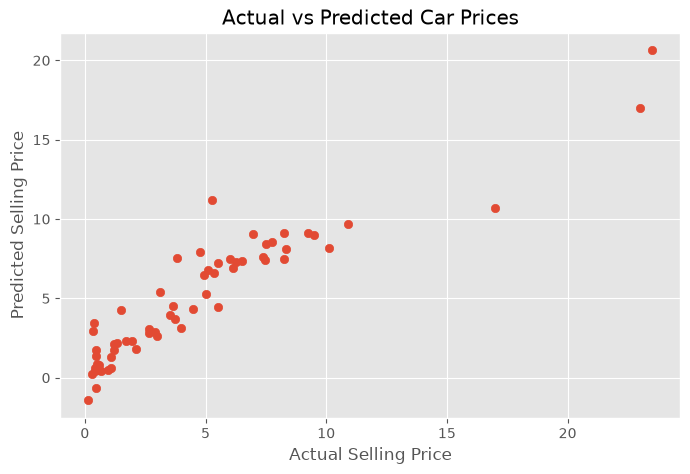

In [62]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Car Prices")

plt.show()

In [66]:
r2=r2_score(y_test,predictions)
print(f"R2 score: {r2}")

R2 score: 0.8489813024899067
